In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_circles

import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.plotting import plot_decision_regions

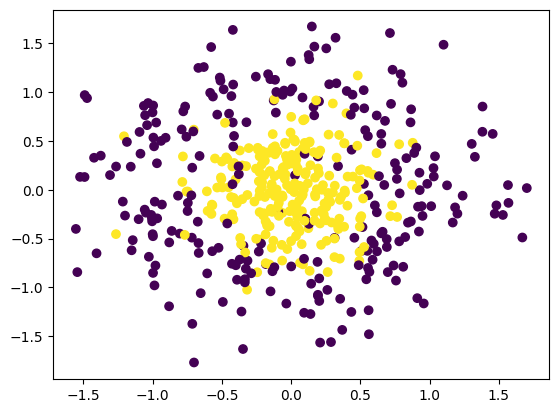

In [2]:
np.random.seed(28)
X,y = make_circles(n_samples=500,noise=0.35,factor=0.1,random_state=28)
plt.scatter(x=X[:,0],y=X[:,1],c=y)

In [3]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_score

In [4]:
ad = AdaBoostClassifier()
np.mean(cross_val_score(ad,X,y,scoring='accuracy',cv=10))

np.float64(0.8619999999999999)

In [5]:
ad.fit(X,y)

AdaBoostClassifier()

In [8]:
def plot_decision_boundary(clf):
    h = 0.02
    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                        np.arange(y_min, y_max, h))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8,6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=plt.cm.coolwarm)
    plt.title("AdaBoost Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()

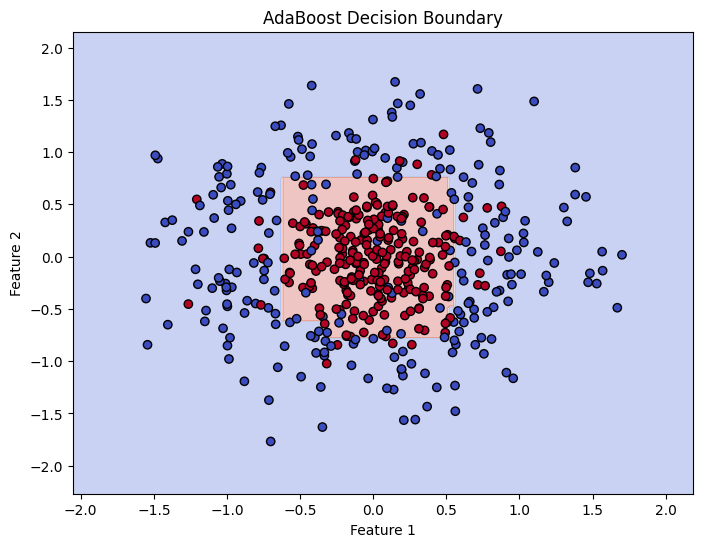

In [9]:
plot_decision_boundary(ad)

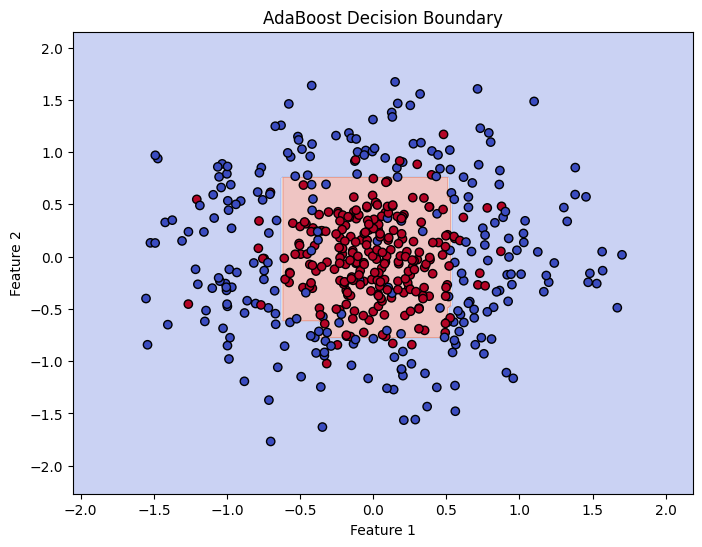

In [17]:
ad = AdaBoostClassifier(n_estimators=500, learning_rate=0.1)
ad.fit(X,y)
plot_decision_boundary(ad)

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

In [27]:
param = {
    'n_estimators': [50, 100, 200, 500,1000],
    'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
    'algorithm': ['SAMME', 'SAMME.R']
}

In [28]:
grid = GridSearchCV(AdaBoostClassifier(), param_grid=param, cv=10, scoring='accuracy', n_jobs=-1)
grid.fit(X,y)

/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(
/Users/sachinchoudhary/.pyenv/versions/3.10.11/lib/python3.10/site-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.wa

GridSearchCV(cv=10, estimator=AdaBoostClassifier(), n_jobs=-1,
             param_grid={'algorithm': ['SAMME', 'SAMME.R'],
                         'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
                         'n_estimators': [50, 100, 200, 500, 1000]},
             scoring='accuracy')

In [29]:
grid.best_score_

np.float64(0.8640000000000001)

In [30]:
grid.best_params_

{'algorithm': 'SAMME', 'learning_rate': 0.5, 'n_estimators': 100}